In [195]:
import os

if "KERAS_BACKEND" not in os.environ:
    # set this to "torch", "tensorflow", or "jax"
    os.environ["KERAS_BACKEND"] = "jax"

In [196]:
import numpy as np

# Define the modified bounded confidence model
def bc_simulator(epsilon_max):
    """Vectorized BC model simulator."""
    if isinstance(epsilon_max, np.ndarray):
        epsilon_max = epsilon_max.item()
    
    epsilon_min = 0 
    alpha = 2 
    beta = 4 
    num_agents = 200
    num_steps = 50 
    rng = np.random.default_rng(None)
    
    # Initialize epsilons and opinions for each agent
    x = rng.gamma(shape=alpha, scale=1.0, size=num_agents)
    y = rng.gamma(shape=beta, scale=1.0, size=num_agents)
    epsilons = epsilon_min + (x / (x + y)) * (epsilon_max - epsilon_min)
    opinions = rng.uniform(0, 1, size=num_agents)
    
    # Vectorized simulation loop
    for t in range(num_steps):
        # Compute pairwise differences (vectorized)
        diffs = np.abs(opinions[:, np.newaxis] - opinions[np.newaxis, :])
        
        # Apply epsilon filtering
        masks = diffs < epsilons[:, np.newaxis]
        
        # Compute new opinions using masked means
        sums = (opinions * masks).sum(axis=1)
        counts = masks.sum(axis=1)
        opinions = np.where(counts > 0, sums / counts, opinions)

    # Add observation noise
    noise_scale = 0.07  # This value can be adjusted --> adjust the observation model
    noisy_opinions = opinions + rng.normal(0, noise_scale, size=num_agents)
    noisy_opinions = np.clip(noisy_opinions, 0, 1)  # Keep in valid range
    
    results = {"opinion_dist": noisy_opinions.reshape(-1, 1).astype(np.float32)}
    
    return results

In [3]:
def priors():
    epsilon_max = np.random.uniform(0.10, 0.60)
    return {
        "epsilon_max": epsilon_max
    }

In [197]:
import bayesflow as bf

# Start the BayesFlow pipeline
simulator = bf.make_simulator([priors, bc_simulator])
simulator

In [198]:
# To properly handle and streamline variables in the two neural networks
adapter = (
    bf.adapters.Adapter()
    .convert_dtype("float64", "float32")
    .rename("epsilon_max", "inference_variables")
    .rename("opinion_dist", "summary_variables")
)

In [611]:
# Let's check out shapes
adapted_sims = adapter(simulator.sample(10)) # Simulate 10 instances of the model from the priors
print(adapted_sims["summary_variables"].shape)
print(adapted_sims["inference_variables"].shape)

(10, 200, 1)
(10, 1)


In [201]:
summary_net = bf.networks.DeepSet(summary_dim = 16) # This can be tweaked (e.g., summary_dim = 24)

In [204]:
inference_net = bf.networks.CouplingFlow()

In [205]:
workflow = bf.BasicWorkflow(
    simulator = simulator,
    adapter = adapter,
    inference_network = inference_net,
    summary_network = summary_net,
    standardize = None # no need to standardize due [0,1] opinions
)

In [206]:
history = workflow.fit_online(epochs = 50, batch_size = 64, num_batches_per_epoch = 100)

INFO:bayesflow:Fitting on dataset instance of OnlineDataset.
INFO:bayesflow:Building on a test batch.


Epoch 1/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 131s 1s/step - loss: -0.2968
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 110s 1s/step - loss: -0.4773
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 116s 1s/step - loss: -0.4899
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 119s 1s/step - loss: -0.9344
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 116s 1s/step - loss: -1.0393
Epoch 6/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 112s 1s/step - loss: -1.0431
Epoch 7/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - loss: -1.1058
Epoch 8/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 117s 1s/step - loss: -1.1475
Epoch 9/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 115s 1s/step - loss: -1.1815
Epoch 10/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 117s 1s/step - loss: -1.2613
Epoch 11/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 110s 1s/step - loss: -1.2770
Epoch 12/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - loss: -1.2824
Epoch 13/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 115s 1s/step - loss: -1.3262
Epoch 14/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 119s 1s/step - loss: -1.3176
Epoch 15/50
100/100 ━━━━━━━━━

In [665]:
seconds_per_epoch = [131, 110, 116, 119, 116, 112, 114, 117, 115, 117, 
 110, 114, 115, 119, 108, 115, 118, 111, 118, 111, 
 240, 133, 132, 132, 133, 135, 136, 136, 133, 135, 
 135, 135, 134, 136, 131, 126, 130, 130, 126, 131, 
 123, 104, 105, 99, 100, 100, 101, 98, 101, 99]

print("Mean is:", np.mean(seconds_per_epoch))
print("95% Interval is:", (np.percentile(seconds_per_epoch, 2.5), np.percentile(seconds_per_epoch, 97.5)))

Mean is: 121.9
95% Interval is: (np.float64(99.0), np.float64(136.0))


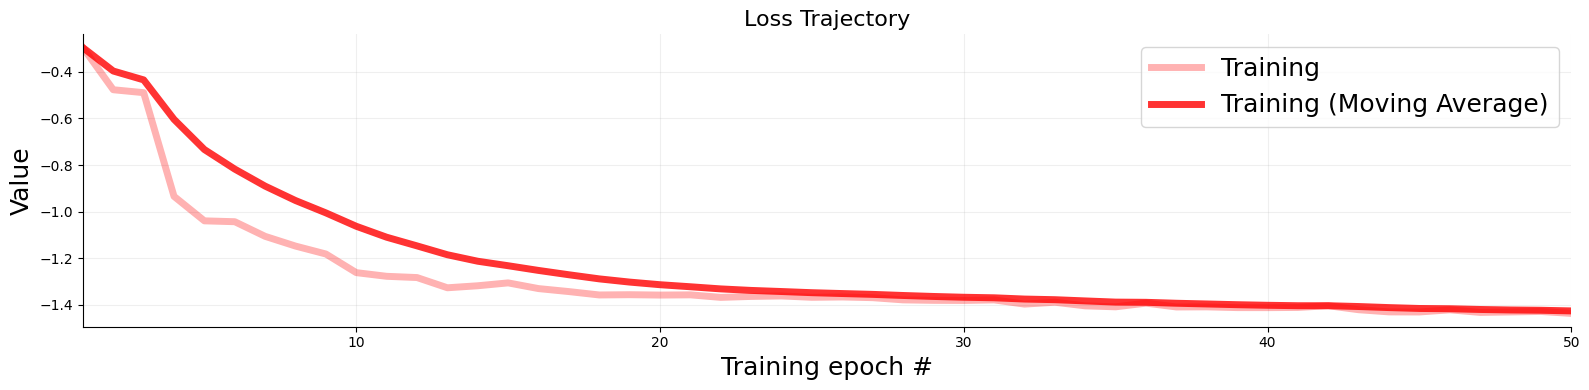

In [612]:
f = bf.diagnostics.plots.loss(history, legend_fontsize = 18, label_fontsize = 18, lw_train = 5,train_color = '#FF0000')

In [249]:
num_datasets = 200
test_sims = workflow.simulate(num_datasets)
# For each simulated dataset we have 3000 posterior samples
samples = workflow.sample(conditions=test_sims, num_samples=3000)

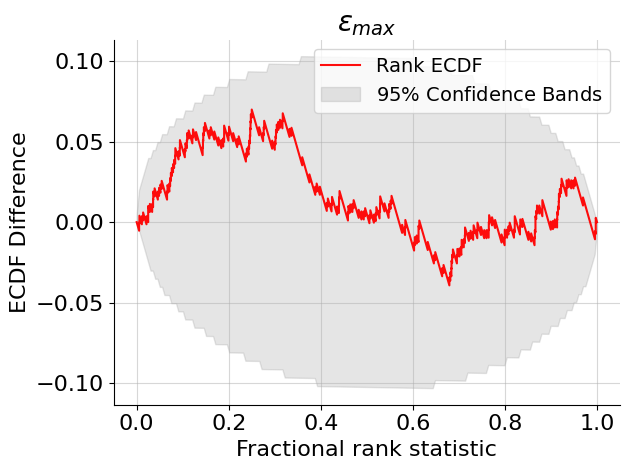

In [615]:
f = bf.diagnostics.plots.calibration_ecdf(samples, 
                                          test_sims, 
                                          difference=True, 
                                          variable_names = [r'$\epsilon_{max}$'],
                                          tick_fontsize = 16,
                                          title_fontsize = 20,
                                          rank_ecdf_color = '#ff0000')
plt.show()

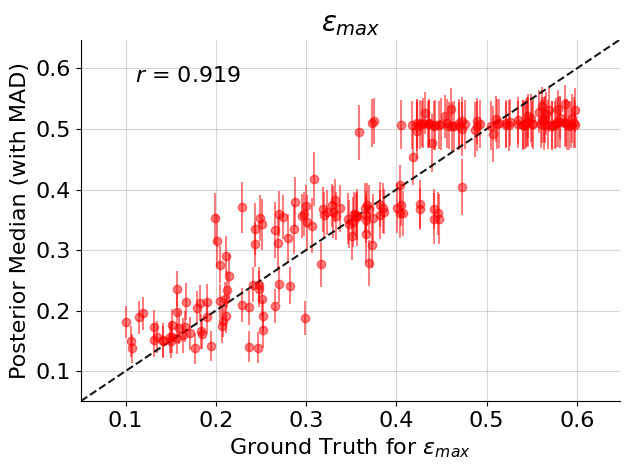

In [616]:
f = bf.diagnostics.plots.recovery(samples, 
                                  test_sims,
                                  variable_names = [r'$\epsilon_{max}$'],
                                  tick_fontsize = 16,
                                  title_fontsize = 20,
                                  color = '#ff0000', 
                                  ylabel = "Posterior Median (with MAD)", 
                                  xlabel = r"Ground Truth for $\epsilon_{max}$")
plt.show()